# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** ______________________ &nbsp;&nbsp; **Roll No.:** ____________ &nbsp;&nbsp; **Date:** ____________

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

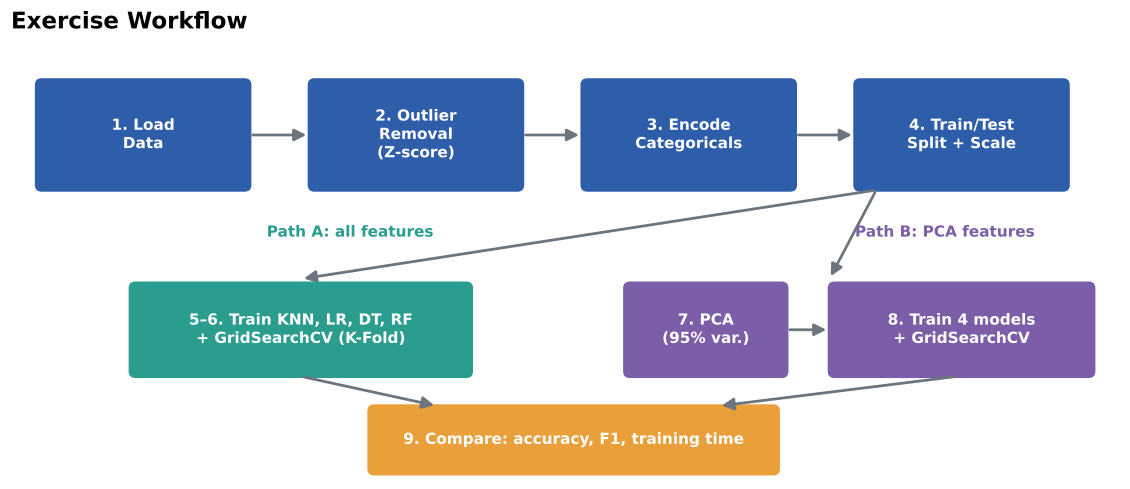

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

---
## Task 1: Load the Dataset

1. Load `heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [2]:
df = pd.read_csv("heart.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [3]:
print("Shape (rows, columns):", df.shape)
print("Columns:", list(df.columns))
df.dtypes

Shape (rows, columns): (918, 12)
Columns: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

### 1.3 Check for missing values

In [4]:
print("Total missing values:", df.isnull().sum().sum())
df.isnull().sum()

Total missing values: 0


Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

HeartDisease
1    508
0    410
Name: count, dtype: int64
HeartDisease
1    55.3 %
0    44.7 %
Name: count, dtype: str


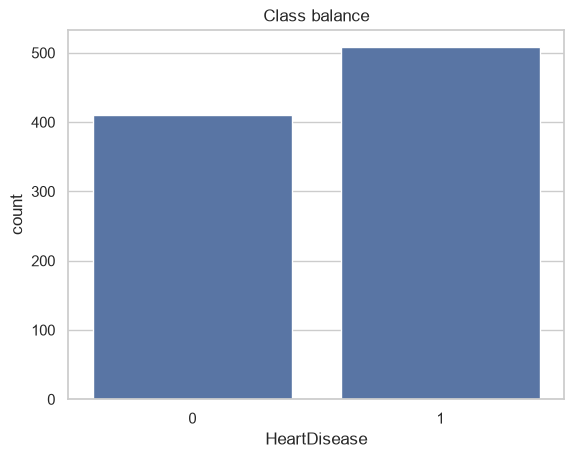

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


In [5]:
counts = df["HeartDisease"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + " %")
sns.countplot(x="HeartDisease", data=df)
plt.title("Class balance")
plt.show()
df.describe().T

**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> ✍️ **Your answer:**
>
> The dataset has **918 rows and 12 columns** (11 features + the target `HeartDisease`). Five columns are text-based: `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina` and `ST_Slope`. There are **no missing values** (`isnull()` is 0 everywhere). However, `describe()` shows hidden missing values: `Cholesterol` has **172 zeros** and `RestingBP` has **1 zero**, which are medically impossible. The classes are fairly balanced (55.3% disease vs 44.7% healthy).

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

![zscore](attachment:zscore.png)

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

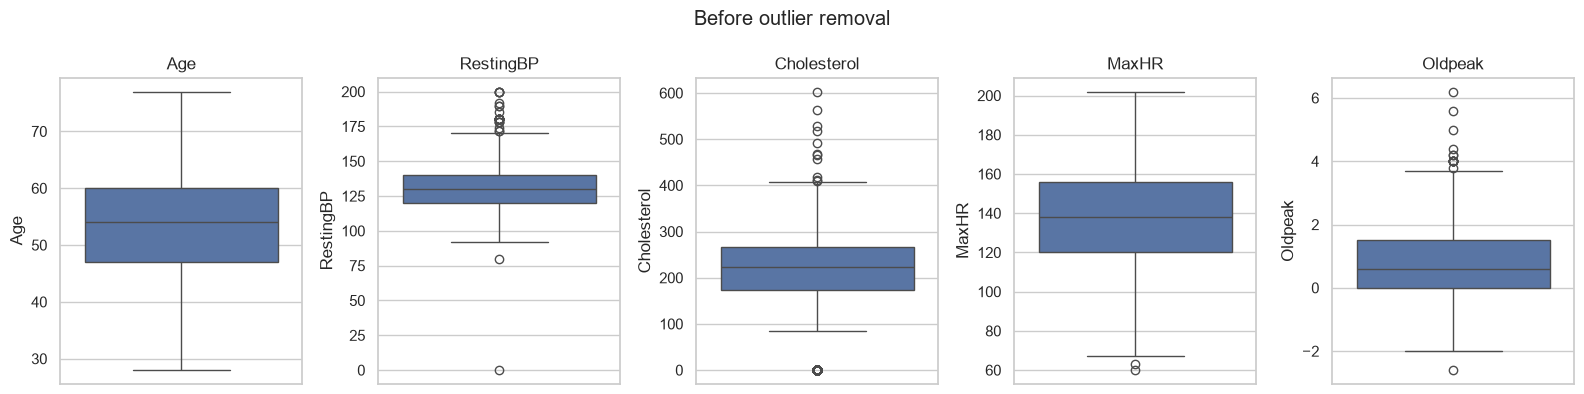

In [6]:
NUM_COLS = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Before outlier removal")
plt.tight_layout()
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [7]:
z_scores = df[NUM_COLS].apply(stats.zscore)
z_scores.head()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.433140,0.410909,0.825070,1.382928,-0.832432
1,-0.478484,1.491752,-0.171961,0.754157,0.105664
2,-1.751359,-0.129513,0.770188,-1.525138,-0.832432
3,-0.584556,0.302825,0.139040,-1.132156,0.574711
4,0.051881,0.951331,-0.034755,-0.581981,-0.832432


### 2.3 Identify and count the outlier records

In [8]:
outlier_flags = z_scores.abs() > 3
print("Outliers per feature:")
print(outlier_flags.sum())
is_outlier = outlier_flags.any(axis=1)
print("\nRecords with at least one outlier:", is_outlier.sum())
df[is_outlier]

Outliers per feature:
Age            0
RestingBP      8
Cholesterol    3
MaxHR          1
Oldpeak        7
dtype: int64

Records with at least one outlier: 19


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
76,32,M,ASY,118,529,0,Normal,130,N,0.0,Flat,1
109,39,M,ATA,190,241,0,Normal,106,N,0.0,Up,0
149,54,M,ASY,130,603,1,Normal,125,Y,1.0,Flat,1
166,50,M,ASY,140,231,0,ST,140,Y,5.0,Flat,1
241,54,M,ASY,200,198,0,Normal,142,Y,2.0,Flat,1
324,46,M,ASY,100,0,1,ST,133,N,-2.6,Flat,1
365,64,F,ASY,200,0,0,Normal,140,Y,1.0,Flat,1
390,51,M,ASY,140,0,0,Normal,60,N,0.0,Flat,1
399,61,M,NAP,200,0,1,ST,70,N,0.0,Flat,1
449,55,M,NAP,0,0,0,Normal,155,N,1.5,Flat,1


### 2.4 Remove the outliers and display the new shape

Before: (918, 12) -> After: (899, 12)
Records removed: 19


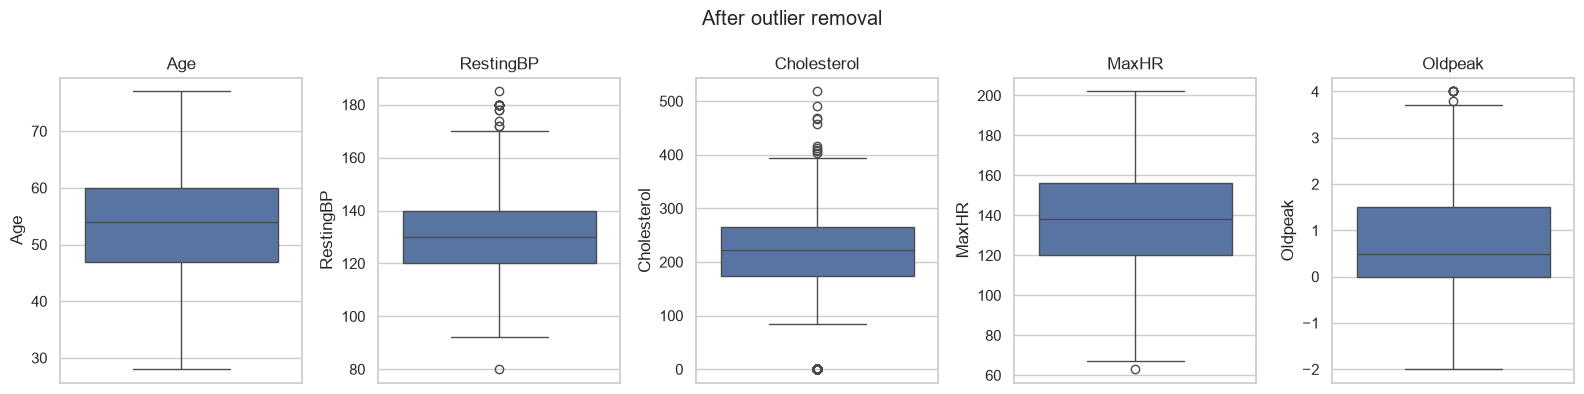

In [9]:
df_clean = df[~is_outlier].reset_index(drop=True)
print("Before:", df.shape, "-> After:", df_clean.shape)
print("Records removed:", len(df) - len(df_clean))
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(col)
plt.suptitle("After outlier removal")
plt.tight_layout()
plt.show()

**Q2.** How many records were removed? Which feature contributed the most outliers?

> ✍️ **Your answer:**
>
> **19 records** were removed (918 -> 899). `RestingBP` contributed the most outliers (**8**), followed by `Oldpeak` (7), `Cholesterol` (3) and `MaxHR` (1); `Age` had none. A record with outliers in several features is counted once.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

![encoding](attachment:encoding.png)

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [10]:
cat_cols = df_clean.select_dtypes(include="object").columns.tolist()
for col in cat_cols:
    print(f"{col:15s} {df_clean[col].nunique()} categories -> {sorted(df_clean[col].unique())}")

Sex             2 categories -> ['F', 'M']
ChestPainType   4 categories -> ['ASY', 'ATA', 'NAP', 'TA']
RestingECG      3 categories -> ['LVH', 'Normal', 'ST']
ExerciseAngina  2 categories -> ['N', 'Y']
ST_Slope        3 categories -> ['Down', 'Flat', 'Up']


### 3.2 Apply Label Encoding

In [11]:
df_enc = df_clean.copy()
binary_cols = ["Sex", "ExerciseAngina"]
for col in binary_cols:
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col])
    print(col, "->", dict(zip(le.classes_, le.transform(le.classes_))))
df_enc[binary_cols].head()

Sex -> {'F': np.int64(0), 'M': np.int64(1)}
ExerciseAngina -> {'N': np.int64(0), 'Y': np.int64(1)}


,Sex,ExerciseAngina
0,1,0
1,0,0
2,1,0
3,0,1
4,1,0


### 3.3 Apply One-Hot Encoding

In [12]:
nominal_cols = ["ChestPainType", "RestingECG", "ST_Slope"]
df_enc = pd.get_dummies(df_enc, columns=nominal_cols, drop_first=True, dtype=int)
print("Columns added by one-hot encoding:")
print([c for c in df_enc.columns if any(c.startswith(n) for n in nominal_cols)])

Columns added by one-hot encoding:
['ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


### 3.4 Display the final encoded dataset

In [13]:
print("Final shape:", df_enc.shape)
print("Remaining text columns:", df_enc.select_dtypes(include="object").columns.tolist())
df_enc.head()

Final shape: (899, 16)
Remaining text columns: []


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

> ✍️ **Your answer:**
>
> `Sex` and `ExerciseAngina` are binary, so **Label Encoding** (one 0/1 column each) is enough and adds no extra columns. `ChestPainType` (4 categories), `RestingECG` (3) and `ST_Slope` (3) are nominal with no natural order, so **One-Hot Encoding** is used; label encoding them would imply a false order (e.g. TA < ATA < NAP). I used `drop_first=True` to avoid redundant columns. The final dataset has **16 columns (15 features + the target)**, up from 12.

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

![leakage](attachment:leakage.png)

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [14]:
X = df_enc.drop(columns="HeartDisease")
y = df_enc["HeartDisease"]
print("X:", X.shape, " y:", y.shape)
print("Features:", list(X.columns))

X: (899, 15)  y: (899,)
Features: ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


### 4.2 Split into training and testing sets

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class share:", y_train.mean().round(3), " Test class share:", y_test.mean().round(3))

Train: (719, 15)  Test: (180, 15)
Train class share: 0.547  Test class share: 0.55


### 4.3 Apply feature scaling (fit on training data only)

In [16]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn mean/std from training data only
X_test_s = scaler.transform(X_test)         # reuse the same parameters on test data
print("Train mean (approx 0):", X_train_s.mean().round(4), " Train std (approx 1):", X_train_s.std().round(4))
print("Test  mean:", X_test_s.mean().round(4), " Test  std:", X_test_s.std().round(4))

Train mean (approx 0): 0.0  Train std (approx 1): 1.0
Test  mean: -0.0005  Test  std: 1.0026


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

> ✍️ **Your answer:**
>
> I used **StandardScaler** (z-score), because KNN depends on distances and logistic regression on gradients, and the features have very different ranges (`Cholesterol` in the hundreds, `Oldpeak` below 7). Fitting the scaler on the whole dataset before splitting would leak the test set's mean and standard deviation into training. The test data would no longer be truly unseen, so the evaluation scores would be optimistic and not trustworthy.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [17]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, show_cm=True):
    """Train a model and return its test metrics, optionally plotting the confusion matrix."""
    start = time.perf_counter()
    model.fit(X_tr, y_tr)
    train_time = time.perf_counter() - start
    pred = model.predict(X_te)
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred),
        "Recall": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
        "Train Time (s)": train_time,
    }
    if show_cm:
        ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                               display_labels=["No disease", "Disease"]).plot(cmap="Blues", colorbar=False)
        plt.title(f"{name} - confusion matrix")
        plt.show()
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()})
    return metrics

baseline_results = []

### 5.2 K-Nearest Neighbors

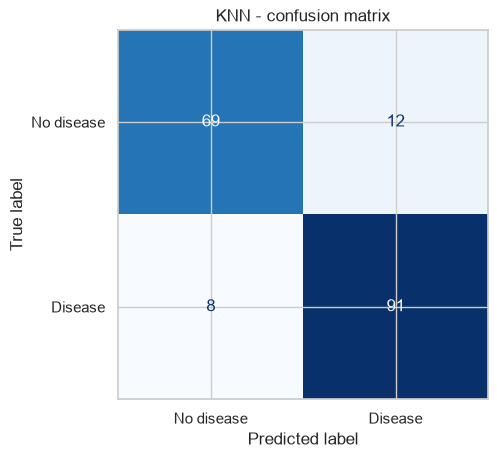

{'Model': 'KNN', 'Accuracy': 0.8889, 'Precision': 0.8835, 'Recall': 0.9192, 'F1': 0.901, 'Train Time (s)': 0.0035}


In [18]:
baseline_results.append(evaluate_model("KNN", KNeighborsClassifier(), X_train_s, y_train, X_test_s, y_test))

### 5.3 Logistic Regression

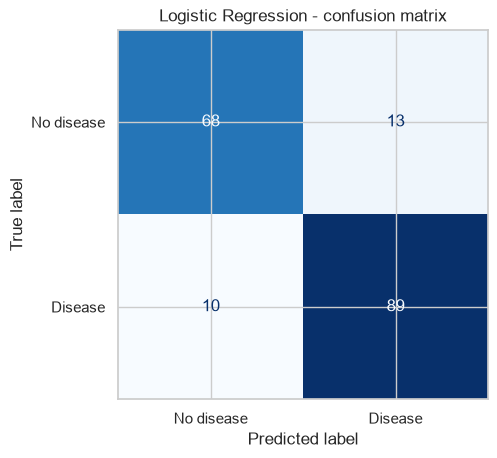

{'Model': 'Logistic Regression', 'Accuracy': 0.8722, 'Precision': 0.8725, 'Recall': 0.899, 'F1': 0.8856, 'Train Time (s)': 0.011}


In [19]:
baseline_results.append(evaluate_model("Logistic Regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                                       X_train_s, y_train, X_test_s, y_test))

### 5.4 Decision Tree

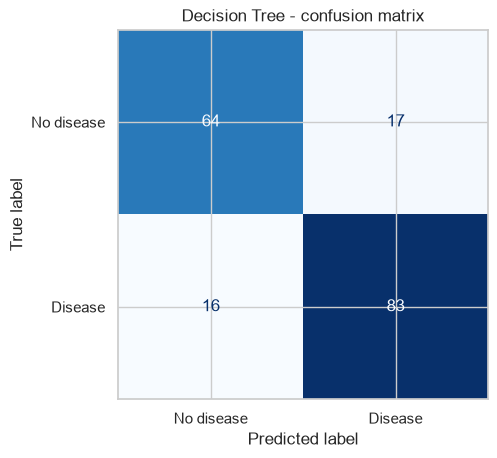

{'Model': 'Decision Tree', 'Accuracy': 0.8167, 'Precision': 0.83, 'Recall': 0.8384, 'F1': 0.8342, 'Train Time (s)': 0.0059}


In [20]:
baseline_results.append(evaluate_model("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE),
                                       X_train_s, y_train, X_test_s, y_test))

### 5.5 Random Forest

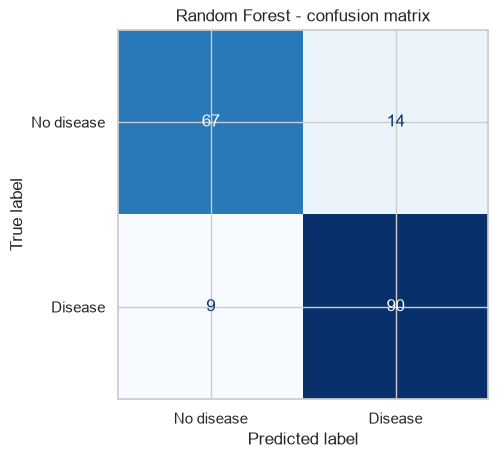

{'Model': 'Random Forest', 'Accuracy': 0.8722, 'Precision': 0.8654, 'Recall': 0.9091, 'F1': 0.8867, 'Train Time (s)': 0.1662}


In [21]:
baseline_results.append(evaluate_model("Random Forest", RandomForestClassifier(random_state=RANDOM_STATE),
                                       X_train_s, y_train, X_test_s, y_test))

### 5.6 Comparison table and bar chart of all four models

,Accuracy,Precision,Recall,F1,Train Time (s)
Model,,,,,
KNN,0.8889,0.8835,0.9192,0.9010,0.0035
Logistic Regression,0.8722,0.8725,0.8990,0.8856,0.0110
Decision Tree,0.8167,0.8300,0.8384,0.8342,0.0059
Random Forest,0.8722,0.8654,0.9091,0.8867,0.1662


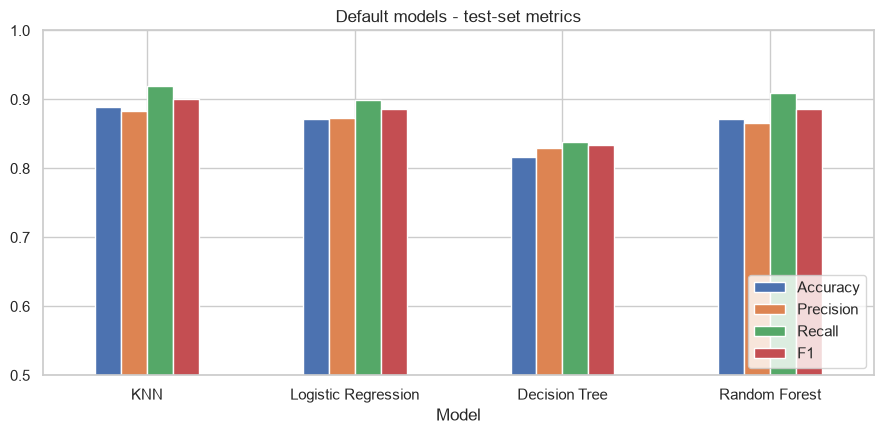

In [22]:
baseline_df = pd.DataFrame(baseline_results).set_index("Model")
display(baseline_df.round(4))
baseline_df[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(9, 4.5), rot=0)
plt.title("Default models - test-set metrics")
plt.ylim(0.5, 1.0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> ✍️ **Your answer:**
>
> With default settings **KNN** had the highest test accuracy (**0.889**), ahead of Logistic Regression and Random Forest (both 0.872) and the Decision Tree (0.817). In medical diagnosis accuracy alone is not enough: a **false negative** (a sick patient told they are healthy) is much more costly than a false positive, so **recall** should be prioritised (with precision/F1 watched so that too many healthy people are not flagged). KNN also has the best recall here (0.919).

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

![kfold](attachment:kfold.png)

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grids = {
    "KNN": (KNeighborsClassifier(),
            {"n_neighbors": [3, 5, 7, 9, 11, 15], "weights": ["uniform", "distance"],
             "metric": ["euclidean", "manhattan"]}),
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
            {"C": [0.01, 0.1, 1, 10, 100], "penalty": ["l2"], "solver": ["lbfgs", "liblinear"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
            {"max_depth": [3, 5, 7, 10, None], "min_samples_split": [2, 5, 10],
             "min_samples_leaf": [1, 2, 4], "criterion": ["gini", "entropy"]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE),
            {"n_estimators": [100, 200], "max_depth": [5, 10, None],
             "min_samples_split": [2, 5], "min_samples_leaf": [1, 2]}),
}

def tune_model(name, X_tr, y_tr, X_te, y_te):
    """Grid-search one model with 5-fold CV, then score the best estimator on the test set."""
    base, grid = param_grids[name]
    search = GridSearchCV(base, grid, cv=cv, scoring="accuracy", n_jobs=1)
    start = time.perf_counter()
    search.fit(X_tr, y_tr)
    train_time = time.perf_counter() - start
    pred = search.best_estimator_.predict(X_te)
    result = {
        "Model": name,
        "Best CV Accuracy": search.best_score_,
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred),
        "Recall": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
        "Train Time (s)": train_time,
        "Best Params": search.best_params_,
    }
    print(name, "->", search.best_params_)
    print(f"   CV acc={result['Best CV Accuracy']:.4f}  test acc={result['Accuracy']:.4f}  "
          f"F1={result['F1']:.4f}  time={train_time:.2f}s")
    return result

tuned_results = []

### 6.2 Tune KNN

In [24]:
tuned_results.append(tune_model("KNN", X_train_s, y_train, X_test_s, y_test))

KNN -> {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
   CV acc=0.8803  test acc=0.8944  F1=0.9055  time=1.10s


### 6.3 Tune Logistic Regression

In [25]:
tuned_results.append(tune_model("Logistic Regression", X_train_s, y_train, X_test_s, y_test))

Logistic Regression -> {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
   CV acc=0.8678  test acc=0.8778  F1=0.8911  time=0.33s


### 6.4 Tune Decision Tree

In [26]:
tuned_results.append(tune_model("Decision Tree", X_train_s, y_train, X_test_s, y_test))

Decision Tree -> {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
   CV acc=0.8344  test acc=0.8222  F1=0.8298  time=2.65s


### 6.5 Tune Random Forest

In [27]:
tuned_results.append(tune_model("Random Forest", X_train_s, y_train, X_test_s, y_test))

Random Forest -> {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
   CV acc=0.8748  test acc=0.8667  F1=0.8824  time=47.18s


### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

In [28]:
tuned_df = pd.DataFrame(tuned_results).set_index("Model")
display(tuned_df.drop(columns="Best Params").round(4))
change = pd.DataFrame({"Default accuracy": baseline_df["Accuracy"],
                       "Tuned accuracy": tuned_df["Accuracy"],
                       "Change": tuned_df["Accuracy"] - baseline_df["Accuracy"]})
display(change.round(4))

,Best CV Accuracy,Accuracy,Precision,Recall,F1,Train Time (s)
Model,,,,,,
KNN,0.8803,0.8944,0.8922,0.9192,0.9055,1.0981
Logistic Regression,0.8678,0.8778,0.8738,0.9091,0.8911,0.3285
Decision Tree,0.8344,0.8222,0.8764,0.7879,0.8298,2.6516
Random Forest,0.8748,0.8667,0.8571,0.9091,0.8824,47.1768


,Default accuracy,Tuned accuracy,Change
Model,,,
KNN,0.8889,0.8944,0.0056
Logistic Regression,0.8722,0.8778,0.0056
Decision Tree,0.8167,0.8222,0.0056
Random Forest,0.8722,0.8667,-0.0056


**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> ✍️ **Your answer:**
>
> Not every model improved. Test accuracy rose slightly for KNN (0.889 -> 0.894), Logistic Regression (0.872 -> 0.878) and the Decision Tree (0.817 -> 0.822), but **Random Forest dropped** (0.872 -> 0.867). Each change is only one test record out of 180, so no model clearly benefited more than another. Tuning helps least where the defaults are already good (Random Forest averages many trees, Logistic Regression is a stable linear model), and a single 180-row test split is too small to separate the models; the cross-validated accuracy (KNN 0.880, Random Forest 0.875, Logistic Regression 0.868, Decision Tree 0.834) is the more reliable guide.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

![pca](attachment:pca.png)

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

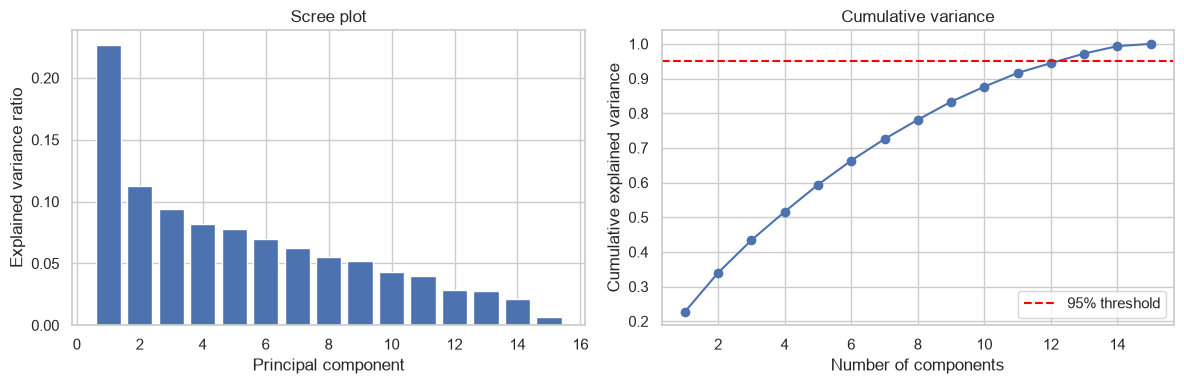

In [29]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_s)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, len(pca_full.explained_variance_ratio_) + 1), pca_full.explained_variance_ratio_)
ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("Explained variance ratio"); ax[0].set_title("Scree plot")
ax[1].plot(range(1, len(cum_var) + 1), cum_var, marker="o")
ax[1].axhline(0.95, color="red", linestyle="--", label="95% threshold")
ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("Cumulative explained variance")
ax[1].set_title("Cumulative variance"); ax[1].legend()
plt.tight_layout()
plt.show()

### 7.2 Determine the number of components for 95% variance

In [30]:
n_components_95 = int(np.argmax(cum_var >= 0.95) + 1)
n_original = X_train_s.shape[1]
print(f"Components needed for 95% variance: {n_components_95} (out of {n_original})")
print(f"Feature reduction: {(1 - n_components_95 / n_original) * 100:.1f}%")

Components needed for 95% variance: 13 (out of 15)
Feature reduction: 13.3%


### 7.3 Transform the training and testing sets

In [31]:
pca = PCA(n_components=n_components_95, random_state=RANDOM_STATE).fit(X_train_s)  # fit on training data only
X_train_pca = pca.transform(X_train_s)
X_test_pca = pca.transform(X_test_s)
print("Train after PCA:", X_train_pca.shape, " Test after PCA:", X_test_pca.shape)
print("Variance retained:", pca.explained_variance_ratio_.sum().round(4))

Train after PCA: (719, 13)  Test after PCA: (180, 13)
Variance retained: 0.972


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

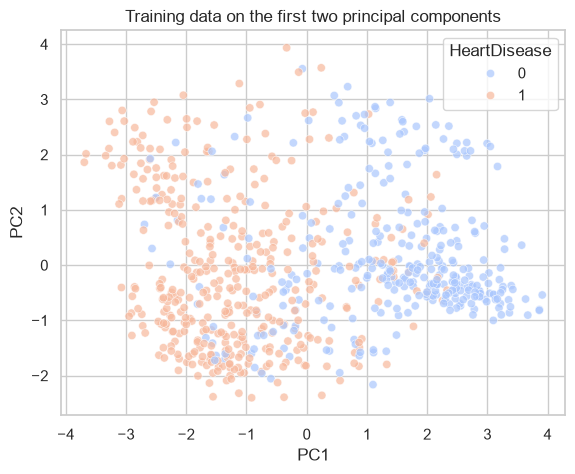

In [32]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_s)
coords = pca2.transform(X_train_s)
plt.figure(figsize=(6.5, 5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=y_train.values, palette="coolwarm", alpha=0.7)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Training data on the first two principal components")
plt.legend(title="HeartDisease")
plt.show()

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> ✍️ **Your answer:**
>
> **13 principal components** are needed to retain at least 95% of the variance (they keep about 97.2%). That reduces the 15 features to 13, a **13.3% reduction**. The reduction is small because most features (one-hot columns especially) carry fairly independent information.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

In [33]:
pca_results = []
pca_results.append(tune_model("KNN", X_train_pca, y_train, X_test_pca, y_test))

KNN -> {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}
   CV acc=0.8762  test acc=0.9111  F1=0.9200  time=1.09s


### 8.2 Logistic Regression after PCA

In [34]:
pca_results.append(tune_model("Logistic Regression", X_train_pca, y_train, X_test_pca, y_test))

Logistic Regression -> {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
   CV acc=0.8678  test acc=0.8778  F1=0.8900  time=0.33s


### 8.3 Decision Tree after PCA

In [35]:
pca_results.append(tune_model("Decision Tree", X_train_pca, y_train, X_test_pca, y_test))

Decision Tree -> {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
   CV acc=0.8345  test acc=0.8722  F1=0.8844  time=5.10s


### 8.4 Random Forest after PCA

In [36]:
pca_results.append(tune_model("Random Forest", X_train_pca, y_train, X_test_pca, y_test))

Random Forest -> {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
   CV acc=0.8706  test acc=0.8889  F1=0.9020  time=41.36s


### 8.5 Comparison table of all four models after PCA

In [37]:
pca_df = pd.DataFrame(pca_results).set_index("Model")
display(pca_df.drop(columns="Best Params").round(4))
print("Best model after PCA:", pca_df["Accuracy"].idxmax(), "| Best model before PCA (tuned):", tuned_df["Accuracy"].idxmax())

,Best CV Accuracy,Accuracy,Precision,Recall,F1,Train Time (s)
Model,,,,,,
KNN,0.8762,0.9111,0.9109,0.9293,0.9200,1.0919
Logistic Regression,0.8678,0.8778,0.8812,0.8990,0.8900,0.3345
Decision Tree,0.8345,0.8722,0.8800,0.8889,0.8844,5.1016
Random Forest,0.8706,0.8889,0.8762,0.9293,0.9020,41.3586


Best model after PCA: KNN | Best model before PCA (tuned): KNN


**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> ✍️ **Your answer:**
>
> After PCA the best model is **KNN** (test accuracy 0.911, F1 0.920), the same model that was best before PCA (0.894). Random Forest (0.889), Logistic Regression (0.878) and the Decision Tree (0.872) follow.

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [38]:
comparison = pd.DataFrame({
    "Accuracy (Before PCA)": tuned_df["Accuracy"],
    "Accuracy (After PCA)": pca_df["Accuracy"],
    "F1 (Before PCA)": tuned_df["F1"],
    "F1 (After PCA)": pca_df["F1"],
    "Training Time Before (s)": tuned_df["Train Time (s)"],
    "Training Time After (s)": pca_df["Train Time (s)"],
    "No. of Features": f"{n_original} -> {n_components_95}",
})
comparison.round(4)

,Accuracy (Before PCA),Accuracy (After PCA),F1 (Before PCA),F1 (After PCA),Training Time Before (s),Training Time After (s),No. of Features
Model,,,,,,,
KNN,0.8944,0.9111,0.9055,0.9200,1.0981,1.0919,15 -> 13
Logistic Regression,0.8778,0.8778,0.8911,0.8900,0.3285,0.3345,15 -> 13
Decision Tree,0.8222,0.8722,0.8298,0.8844,2.6516,5.1016,15 -> 13
Random Forest,0.8667,0.8889,0.8824,0.9020,47.1768,41.3586,15 -> 13


### 9.2 Visualise the before vs after PCA comparison

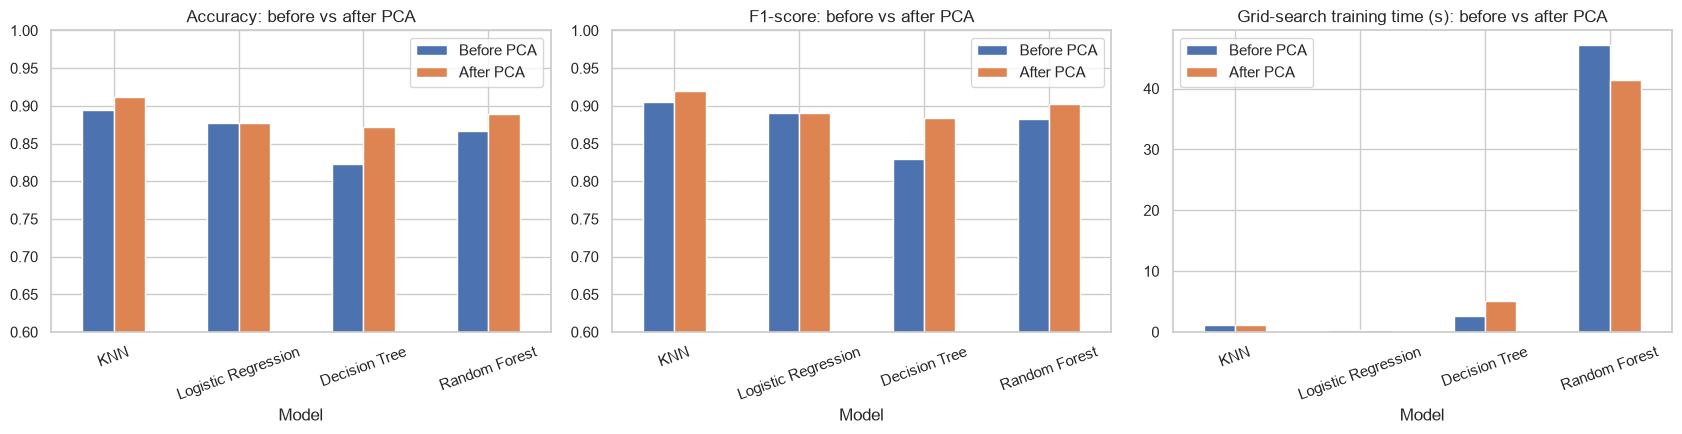

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (before, after, title) in zip(axes, [
        ("Accuracy (Before PCA)", "Accuracy (After PCA)", "Accuracy"),
        ("F1 (Before PCA)", "F1 (After PCA)", "F1-score"),
        ("Training Time Before (s)", "Training Time After (s)", "Grid-search training time (s)")]):
    comparison[[before, after]].plot(kind="bar", ax=ax, rot=20)
    ax.set_title(f"{title}: before vs after PCA")
    ax.legend(["Before PCA", "After PCA"])
    if title != "Grid-search training time (s)":
        ax.set_ylim(0.6, 1.0)
plt.tight_layout()
plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> ✍️ **Your answer:**
>
> Accuracy improved for KNN (0.894 -> 0.911), Decision Tree (0.822 -> 0.872) and Random Forest (0.867 -> 0.889), and stayed the same for Logistic Regression (0.878). F1 behaved the same way, except Logistic Regression's F1 dipped marginally (0.891 -> 0.890). No model got meaningfully worse. Note that these differences are a few test records out of 180, so they should be read as 'about the same or slightly better' rather than a firm improvement.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**
>
> PCA cut the input from 15 to 13 features, which is a small saving, and the grid-search training times before and after are about the same order (the same grids were searched; the small differences are mostly timing noise on this machine). On a dataset this small (719 training rows) training is already fast, so PCA gives no real speed benefit here. The efficiency gain would only matter with hundreds or thousands of features or millions of rows.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> ✍️ **Your answer:**
>
> On this dataset PCA left performance **unchanged or slightly better**. Possible reasons: (1) only 2 of 15 dimensions were dropped, so almost no information was lost (97.2% variance kept); (2) the dropped low-variance directions may be mostly noise, which helps distance-based KNN and the tree models that overfit; (3) the dataset is small, so a little regularisation from PCA can help; (4) Logistic Regression is already a smooth linear model, so it is unaffected. The cost is **interpretability**: principal components are mixtures of the original features, so a doctor can no longer say which clinical measurement drives a prediction.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**
>
> Reducing dimensions usually lowers computational cost and memory and can reduce overfitting, but it may lose some predictive information and always loses interpretability. The right balance depends on the problem: a high-stakes medical model with few features may prefer the original, explainable features, whereas PCA is attractive for **high-dimensional data** (images, genomics, text, sensor data), for removing correlated features, for visualisation in 2D/3D, and when training or serving time and storage are limiting.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.